# Học Machine Learning với dữ liệu điểm học sinh

Notebook này dạy từng bước: linear regression, logistic regression, cây quyết định và random forest. Mỗi bước có phần giải thích, việc cần làm và kết quả mong đợi để bạn tự kiểm tra.

Chuẩn bị:
1. Đặt file data1.csv cùng thư mục với notebook.
2. Cài thư viện nếu chưa có: pip install pandas numpy matplotlib scikit-learn statsmodels

Cách làm: đọc phần giải thích, viết code vào ô trống, chạy bằng Shift + Enter, rồi so sánh với kết quả mong đợi. Nếu kết quả khác, đọc lại đề bài và thử lại trước khi xem đáp án.

## Bước 0: Import thư viện

Mục tiêu: nạp các thư viện dùng trong toàn bộ notebook. Ô này đã viết sẵn, bạn chỉ cần chạy.

In [87]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeRegressor, export_text
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, accuracy_score, roc_auc_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.inspection import permutation_importance

## Bước 1: Đọc dữ liệu

Mục tiêu: đưa file CSV vào bộ nhớ dưới dạng DataFrame của pandas, rồi kiểm tra kích thước.

Kiến thức: pd.read_csv đọc file thành bảng. df.shape trả về (số dòng, số cột).

Kết quả mong đợi: (649, 33).

In [88]:
# Viết code ở đây:
# 1. Đọc file data1.csv vào biến df (gợi ý: pd.read_csv)
# 2. In kích thước của df (gợi ý: df.shape)
df = pd.read_csv('data1.csv')
print(data.shape)

(649, 33)


## Bước 2: Xem tổng quan

Mục tiêu: xem vài dòng đầu, kiểu dữ liệu của từng cột, và kiểm tra giá trị thiếu.

Kiến thức: head() xem các dòng đầu, info() cho biết kiểu dữ liệu, isna().sum() đếm ô trống.

Kết quả mong đợi: 17 cột chuỗi, 16 cột số, 0 ô trống.

Câu hỏi: tại sao phải kiểm tra giá trị thiếu trước khi huấn luyện mô hình?

In [89]:
# Viết code ở đây:
# 1. In 5 dòng đầu của df (gợi ý: print(df.head()))
# 2. Xem kiểu dữ liệu của các cột (gợi ý: df.info())
# 3. Đếm số ô bị thiếu trong toàn bảng (gợi ý: isna() rồi sum() hai lần)
print(df.head(5))
print(df.info())
print(df.isna().sum().sum())


  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  ...  \
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  ...   
1     GP   F   17       U     GT3       T     1     1  at_home     other  ...   
2     GP   F   15       U     LE3       T     1     1  at_home     other  ...   
3     GP   F   15       U     GT3       T     4     2   health  services  ...   
4     GP   F   16       U     GT3       T     3     3    other     other  ...   

  famrel freetime  goout  Dalc  Walc health absences  G1  G2  G3  
0      4        3      4     1     1      3        4   0  11  11  
1      5        3      3     1     1      3        2   9  11  11  
2      4        3      2     2     3      3        6  12  13  12  
3      3        2      2     1     1      5        0  14  14  14  
4      4        3      2     1     2      5        0  11  13  13  

[5 rows x 33 columns]
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (to

## Bước 3: Phân phối điểm G3

Mục tiêu: xem G3 phân bố thế nào và có điểm bất thường không.

Kiến thức: value_counts() đếm số lần xuất hiện của mỗi giá trị. plt.hist vẽ biểu đồ phân phối.

Kết quả mong đợi: 15 học sinh có G3 = 0. Phần lớn điểm nằm từ 8 đến 15.

Câu hỏi: điểm 0 có nghĩa gì trong thực tế? Bạn có nên giữ những dòng này không?

G3
0      15
1       1
5       1
6       3
7      10
8      35
9      35
10     97
11    104
12     72
13     82
14     63
15     49
16     36
17     29
18     15
19      2
Name: count, dtype: int64
Số học sinh có G3 = 0: 15


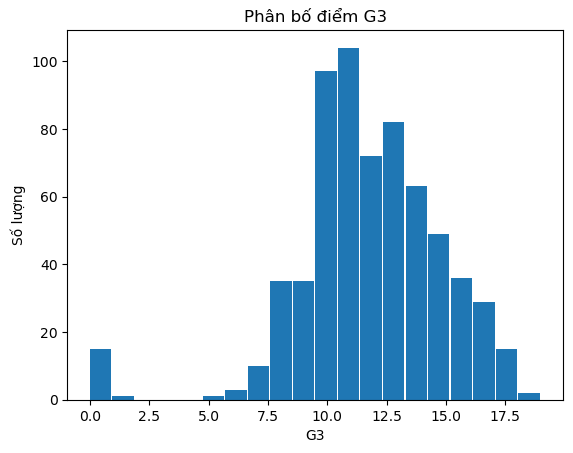

In [90]:
# Viết code ở đây:
# 1. Đếm số học sinh theo từng giá trị G3, sắp xếp theo giá trị (value_counts, sort_index)
# 2. Đếm số học sinh có G3 = 0
# 3. Vẽ histogram của G3 với 20 cột (plt.hist)

g3_counts = df['G3'].value_counts().sort_index()
print(g3_counts)

g3_zero_count = df[df['G3'] == 0].shape[0]
print(f"Số học sinh có G3 = 0: {g3_zero_count}")

plt.hist(df['G3'], bins=20, width=0.9)
plt.xlabel('G3')
plt.ylabel('Số lượng')
plt.title('Phân bố điểm G3')
plt.show()


## Bước 4: Tương quan với G3

Mục tiêu: xem biến nào có liên hệ tuyến tính mạnh với G3.

Kiến thức: corr() tính hệ số tương quan Pearson giữa các cột số, giá trị từ -1 đến 1. select_dtypes('number') chọn các cột số.

Kết quả mong đợi: G2 khoảng 0,919, G1 khoảng 0,826.

Câu hỏi: tại sao G2 gần như trùng với G3? Điều này ảnh hưởng thế nào đến việc đánh giá mô hình?

G3            1.000
G2            0.919
G1            0.826
studytime     0.250
Medu          0.240
Fedu          0.212
famrel        0.063
goout        -0.088
absences     -0.091
health       -0.099
age          -0.107
freetime     -0.123
traveltime   -0.127
Walc         -0.177
Dalc         -0.205
failures     -0.393
Name: G3, dtype: float64


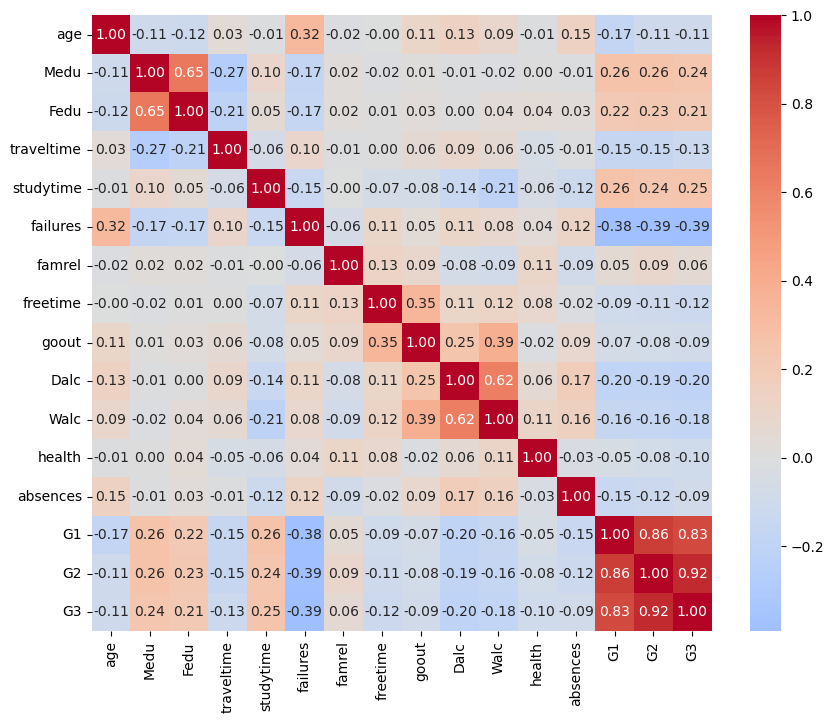

In [91]:
# Viết code ở đây:
# 1. Lấy các cột số: df.select_dtypes('number')
# 2. Tính ma trận tương quan (corr), rồi lấy cột G3
# 3. Sắp xếp giảm dần và in ra, làm tròn 3 chữ số

numeric_cols = df.select_dtypes(include='number')
correlation_matrix = numeric_cols.corr()
g3_correlation = correlation_matrix['G3'].sort_values(ascending=False).round(3)
print(g3_correlation)

plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', center=0)
plt.show()

## Bước 5: Mã hóa các cột có hai giá trị

Mục tiêu: đổi các cột chữ có hai giá trị (yes/no, F/M) thành số 0 và 1. Hồi quy chỉ làm việc với số.

Kiến thức: astype('category').cat.codes gán mã số theo thứ tự chữ cái. Ví dụ 'no' thành 0 và 'yes' thành 1, 'F' thành 0 và 'M' thành 1.

Kết quả mong đợi: mỗi cột trong binary_cols chỉ còn giá trị 0 hoặc 1.

In [92]:
binary_cols = ['sex', 'schoolsup', 'famsup', 'paid', 'higher', 'internet', 'romantic']

# Viết code ở đây: với mỗi cột trong binary_cols, đổi thành mã số bằng cat.codes
# Gợi ý: dùng vòng lặp for và gán lại vào df[c]
for c in binary_cols:
    df[c] = df[c].astype('category').cat.codes
print(df[binary_cols].head())


   sex  schoolsup  famsup  paid  higher  internet  romantic
0    0          1       0     0       1         0         0
1    0          0       1     0       1         1         0
2    0          1       0     0       1         1         0
3    0          0       1     0       1         1         1
4    0          0       1     0       1         0         0


## Bước 6: Chọn feature và tạo biến mục tiêu

Mục tiêu: tạo hai bộ feature (setup A và setup B) và tách biến mục tiêu y.

Kiến thức: feature là danh sách tên cột. df[danh_sách] lấy ra nhiều cột cùng lúc. Setup A không có G1 và G2. Setup B thêm hai cột này vào.

Kết quả mong đợi: len(feat_A) = 20, len(feat_B) = 22.

Câu hỏi: nếu dùng setup B để dự đoán điểm cho học sinh chưa thi kỳ nào, có được không? Vì sao?

In [93]:
feat_A = ['sex', 'age', 'Medu', 'Fedu', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid',
          'higher', 'internet', 'romantic', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'traveltime', 'freetime', 'famrel']

# Viết code ở đây:
# 1. Tạo feat_B bằng cách cộng feat_A với ['G1', 'G2']
# 2. Tạo X_A = df[feat_A], X_B = df[feat_B], y = df['G3']
# 3. In độ dài của feat_A và feat_B
feat_B = feat_A + ['G1', 'G2']
X_A = df[feat_A]
X_B = df[feat_B]
y = df['G3']
print(f"Độ dài của feat_A: {len(feat_A)}")
print(f"Độ dài của feat_B: {len(feat_B)}")

Độ dài của feat_A: 20
Độ dài của feat_B: 22


## Bước 7: Chia tập train và test

Mục tiêu: giữ lại 20% dữ liệu để kiểm tra mô hình trên dữ liệu chưa thấy.

Kiến thức: train_test_split chia ngẫu nhiên. random_state=42 giữ kết quả cố định mỗi lần chạy. Mô hình chỉ học trên tập train. Kết quả trên tập test mới cho biết khả năng dự đoán thật.

Kết quả mong đợi: X_test_A có 130 dòng và 20 cột.

In [94]:
# Viết code ở đây:
# 1. Chia X_A và y thành X_train_A, X_test_A, y_train, y_test
#    (test_size=0.2, random_state=42)
# 2. Chia X_B tương tự thành X_train_B, X_test_B (không cần lấy lại y)
# 3. In kích thước của X_test_A

X_train_A, X_test_A, y_train, y_test = train_test_split(X_A, y, test_size=0.2, random_state=42)
X_train_B, X_test_B, _, _ = train_test_split(X_B, y, test_size=0.2, random_state=42)
print(f"Kích thước của X_test_A: {X_test_A.shape}")

Kích thước của X_test_A: (130, 20)


## Bước 8: Linear regression với sklearn

Mục tiêu: huấn luyện hồi quy tuyến tính và đo độ chính xác trên tập test.

Kiến thức: quy trình của sklearn có ba bước: tạo mô hình, fit trên tập train, predict trên tập test. R² đo tỷ lệ phương sai được giải thích, 1 là hoàn hảo, dưới 0 là tệ hơn việc đoán trung bình. MAE là sai số trung bình tuyệt đối, tính theo đơn vị điểm.

Kết quả mong đợi: R² test khoảng 0,219. MAE khoảng 2,07.

Câu hỏi: nếu luôn đoán bằng điểm trung bình của tập train, MAE là bao nhiêu? So sánh với 2,07.

In [95]:
# Viết code ở đây:
# 1. Tạo LinearRegression(), fit trên X_train_A và y_train
# 2. Dự đoán trên X_test_A và lưu vào pred
# 3. In R² và MAE trên tập test (làm tròn 3 và 2 chữ số)
# 4. Tính MAE của cách đoán luôn bằng y_train.mean()

model_A = LinearRegression()
model_A.fit(X_train_A, y_train)
pred_A = model_A.predict(X_test_A)
r2_A = r2_score(y_test, pred_A)
mae_A = mean_absolute_error(y_test, pred_A)
mae_baseline = mean_absolute_error(y_test, [y_train.mean()] * len(y_test))
print(f"R² trên tập test: {r2_A:.3f}")
print(f"MAE trên tập test: {mae_A:.2f}")
print(f"MAE của cách đoán luôn bằng y_train.mean(): {mae_baseline:.2f}")    

R² trên tập test: 0.219
MAE trên tập test: 2.07
MAE của cách đoán luôn bằng y_train.mean(): 2.39


## Bước 9: Đọc bảng thống kê với statsmodels

Mục tiêu: đọc hệ số, p-value và khoảng tin cậy. sklearn không đưa các thông tin này, nên dùng statsmodels cho phần suy luận.

Kiến thức: sm.add_constant thêm cột hằng số (intercept). sm.OLS là bình phương tối thiểu thông thường, tương đương linear regression. Cột P>|t| trong bảng là p-value. Cột coef là thay đổi trung bình của G3 khi biến tăng một đơn vị, giữ các biến khác cố định.

Kết quả mong đợi: R² khoảng 0,304. Lưu ý đây là R² trên toàn bộ dữ liệu, không phải tập test.

Câu hỏi: viết một câu tiếng Việt giải thích hệ số của failures.

In [109]:
# Viết code ở đây:
# 1. Thêm cột hằng số vào X_A (sm.add_constant, ép kiểu float)
# 2. Fit mô hình sm.OLS với y
# 3. In toàn bộ summary (gợi ý: .summary())

X_A_const = sm.add_constant(X_A.astype(float))
model_ols = sm.OLS(y, X_A_const).fit()
print(model_ols.summary())


                            OLS Regression Results                            
Dep. Variable:                     G3   R-squared:                       0.304
Model:                            OLS   Adj. R-squared:                  0.282
Method:                 Least Squares   F-statistic:                     13.72
Date:                Sat, 10 Oct 2026   Prob (F-statistic):           8.24e-38
Time:                        21:52:15   Log-Likelihood:                -1563.8
No. Observations:                 649   AIC:                             3170.
Df Residuals:                     628   BIC:                             3264.
Df Model:                          20                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          7.4980      1.886      3.975      0.0

## Bước 10: Lọc các biến có ý nghĩa thống kê

Mục tiêu: lấy ra các biến có p-value dưới 0,05.

Kiến thức: ols.pvalues là một Series. Lọc bằng điều kiện ols.pvalues < 0.05, rồi bỏ hằng số bằng drop('const').

Kết quả mong đợi: 7 biến gồm studytime, failures, schoolsup, higher, internet, romantic, health. Hãy đối chiếu với bảng bạn vừa in.

Gợi ý thêm: thử fit OLS với feat_B (setup B) rồi xem biến nào mất ý nghĩa. Câu trả lời sẽ cho thấy điểm trước đó đã "hấp thụ" ảnh hưởng của những biến nào.

In [110]:
# Viết code ở đây:
# 1. Lọc ols.pvalues có giá trị nhỏ hơn 0.05
# 2. Bỏ 'const' khỏi kết quả (drop)
# 3. Sắp xếp và in ra

significant_vars = model_ols.pvalues[model_ols.pvalues < 0.05].index.drop('const')
significant_vars = significant_vars.sort_values()
print(significant_vars)

Index(['failures', 'health', 'higher', 'internet', 'romantic', 'schoolsup',
       'studytime'],
      dtype='object')


## Bước 11: Kiểm tra phần dư

Mục tiêu: vẽ phần dư (residual) để kiểm tra giả định của linear regression.

Kiến thức: phần dư bằng giá trị thực trừ giá trị dự đoán. Nếu mô hình ổn, các điểm nên phân tán ngẫu nhiên quanh đường 0 và không tạo hình dạng rõ ràng. Phần dư lớn bất thường thường đến từ các điểm ngoại lai.

Kết quả mong đợi: 15 học sinh có G3 = 0 đều có phần dư âm lớn, từ khoảng -5 đến -14.

Câu hỏi: nhóm điểm này có làm lệch đường hồi quy không? Bạn sẽ xử lý thế nào?

Phần dư của các học sinh có y == 0:
163    -5.816870
440    -9.917275
519   -13.101334
563    -9.136059
567    -8.809166
583    -8.836258
586   -12.055740
597   -10.632416
603   -13.471918
605    -8.139626
610    -5.500825
626   -12.566661
637   -11.251438
639    -9.828090
640    -9.285956
dtype: float64


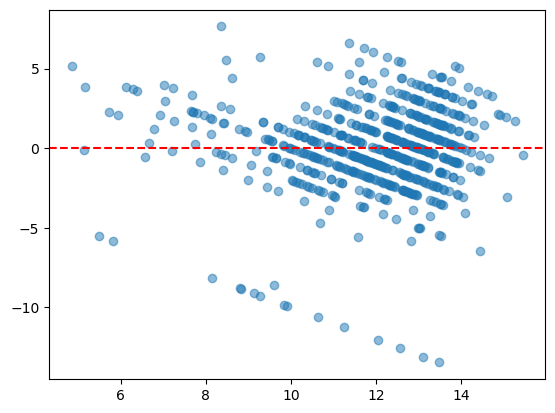

0.0002040949180279733


In [114]:
# Viết code ở đây:
# 1. Vẽ scatter: trục x là ols.fittedvalues, trục y là ols.resid (alpha=0.5)
# 2. Vẽ đường ngang tại y = 0 (plt.axhline, màu đỏ)
# 3. In phần dư của các học sinh có y == 0 (gợi ý: ols.resid[y == 0])
from statsmodels.stats.diagnostic import het_breuschpagan

plt.scatter(model_ols.fittedvalues, model_ols.resid, alpha=0.5)
plt.axhline(y=0, color='red', linestyle='--')
residuals_y_zero = model_ols.resid[y == 0]
print("Phần dư của các học sinh có y == 0:")
print(residuals_y_zero)
plt.show()
lm, lm_pvalue, f, f_pvalue = het_breuschpagan(model_ols.resid, model_ols.model.exog)
print(lm_pvalue)

## Bước 12: Cross-validation

Mục tiêu: đánh giá mô hình ổn định hơn một lần chia train/test.

Kiến thức: 5-fold chia dữ liệu thành 5 phần. Mỗi lần, một phần làm test và bốn phần còn lại làm train. Lấy trung bình của 5 lần.

Kết quả mong đợi: R² trung bình khoảng 0,126.

Câu hỏi: so với R² 0,304 ở bước 9, con số này nói lên điều gì về việc đánh giá mô hình trên dữ liệu đã dùng để huấn luyện?

In [115]:
# Viết code ở đây:
# 1. Dùng cross_val_score với LinearRegression(), X_A, y, cv=5, scoring='r2'
# 2. In từng điểm số (làm tròn 3 chữ số) và giá trị trung bình

cv_scores = cross_val_score(LinearRegression(), X_A, y, cv=5, scoring='r2')
print("Điểm số R² từ cross-validation:")
for i, score in enumerate(cv_scores):
    print(f"Fold {i+1}: {score:.3f}")
print(f"Giá trị trung bình R²: {cv_scores.mean():.3f}")


Điểm số R² từ cross-validation:
Fold 1: -0.077
Fold 2: 0.256
Fold 3: 0.199
Fold 4: 0.227
Fold 5: 0.024
Giá trị trung bình R²: 0.126


## Bước 13: Logistic regression, chuẩn bị biến mục tiêu

Mục tiêu: đổi bài toán thành phân loại đậu hay trượt.

Kiến thức: (y >= 10).astype(int) cho ra 1 nếu đậu và 0 nếu trượt. Baseline accuracy là tỷ lệ của lớp lớn nhất. Một mô hình chỉ đoán lớp đó vẫn đạt đúng tỷ lệ này.

Kết quả mong đợi: tỷ lệ đậu khoảng 0,846.

Câu hỏi: nếu chỉ nhìn accuracy, một mô hình luôn đoán "đậu" đạt bao nhiêu? Điều này cho thấy gì về việc chọn chỉ số đánh giá?

In [116]:
# Viết code ở đây:
# 1. Tạo ypass = 1 nếu y >= 10, còn lại là 0 (gợi ý: .astype(int))
# 2. In tỷ lệ đậu (trung bình của ypass) làm tròn 3 chữ số

ypass = (y >= 10).astype(int)
print(f"Tỷ lệ đậu: {ypass.mean():.3f}")

Tỷ lệ đậu: 0.846


## Bước 14: Logistic regression, setup A

Mục tiêu: huấn luyện logistic regression trên setup A và đo accuracy và AUC.

Kiến thức: StandardScaler đưa các cột về cùng thang đo, điều này cần thiết cho logistic có regularization. make_pipeline gộp các bước lại. stratify=ypass giữ tỷ lệ đậu và trượt giống nhau ở hai tập. AUC đo khả năng xếp hạng: 0,5 là đoán ngẫu nhiên, 1 là hoàn hảo. Dùng predict_proba để lấy xác suất.

Kết quả mong đợi: accuracy khoảng 0,785, AUC khoảng 0,534.

Câu hỏi: accuracy này cao hơn hay thấp hơn baseline ở bước 13?

In [117]:
# Viết code ở đây:
# 1. Chia X_A và ypass thành Xtr_A, Xte_A, ptr, pte
#    (test_size=0.2, random_state=42, stratify=ypass)
# 2. Tạo pipeline gồm StandardScaler() và LogisticRegression(max_iter=2000)
# 3. Fit trên tập train
# 4. In accuracy và AUC trên tập test (AUC dùng predict_proba(...)[:, 1])

xtr_A, xte_A, ptr, pte = train_test_split(X_A, ypass, test_size=0.2, random_state=42, stratify=ypass)
pipeline = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
pipeline.fit(xtr_A, ptr)
predictions = pipeline.predict(xte_A)
accuracy = accuracy_score(pte, predictions)
auc = roc_auc_score(pte, pipeline.predict_proba(xte_A)[:, 1])
print(f"Accuracy trên tập test: {accuracy:.3f}")
print(f"AUC trên tập test: {auc:.3f}")


Accuracy trên tập test: 0.785
AUC trên tập test: 0.534


## Bước 15: Viết hàm để chạy lại cho setup B

Mục tiêu: gói quy trình ở bước 14 vào một hàm, rồi dùng lại cho cả setup A và setup B. Viết hàm giúp tránh copy code và giảm lỗi.

Kiến thức: def tên_hàm(tham_số): định nghĩa hàm. Hàm có thể trả về giá trị bằng return.

Kết quả mong đợi: setup B có accuracy khoảng 0,892 và AUC khoảng 0,957.

Câu hỏi: vì sao AUC tăng mạnh khi thêm G1 và G2? Gợi ý: nhìn lại tương quan ở bước 4.

In [102]:
# Viết hàm run_logistic(X, name):
# 1. Chia X và ypass thành train/test (stratify=ypass, random_state=42, test_size=0.2)
# 2. Tạo pipeline StandardScaler + LogisticRegression(max_iter=2000) rồi fit
# 3. Tính accuracy và AUC trên tập test, in ra cùng với name
# 4. Return mô hình
# Sau đó gọi hàm cho X_A và X_B


## Bước 16: Odds ratio

Mục tiêu: đổi hệ số log-odds thành odds ratio để dễ đọc.

Kiến thức: sm.Logit là logistic regression trong statsmodels, cho p-value. Odds ratio bằng exp(coef). OR lớn hơn 1 nghĩa là khi biến tăng thì khả năng đậu tăng.

Kết quả mong đợi: OR của G2 khoảng 5,08. OR của G1 khoảng 2,15. OR của age khoảng 1,85 với p-value khoảng 0,003.

Câu hỏi: age có OR lớn và có ý nghĩa thống kê. Bạn nghĩ có thể giải thích thế nào? Nếu không chắc, ghi rõ đó là giả thuyết cần kiểm tra thêm.

In [119]:
# Viết code ở đây:
# 1. Thêm hằng số vào X_B (float), rồi fit sm.Logit(ypass, ...) với disp=0
# 2. Tạo DataFrame gồm cột OR = exp(params) và cột p-value (pvalues)
# 3. In các dòng G1, G2 và age (làm tròn 3 chữ số)

added_constant_X_B = sm.add_constant(X_B.astype(float))
logit_model = sm.Logit(ypass, added_constant_X_B).fit(disp=0)
odds_ratios = np.exp(logit_model.params)
p_values = logit_model.pvalues
results_df = pd.DataFrame({'OR': odds_ratios, 'p-value': p_values})
print(results_df.loc[['G1', 'G2', 'age']].round(3))
print(logit_model.summary())


        OR  p-value
G1   2.151    0.000
G2   5.079    0.000
age  1.849    0.003
                           Logit Regression Results                           
Dep. Variable:                     G3   No. Observations:                  649
Model:                          Logit   Df Residuals:                      626
Method:                           MLE   Df Model:                           22
Date:                Sun, 11 Oct 2026   Pseudo R-squ.:                  0.6993
Time:                        01:18:05   Log-Likelihood:                -83.870
converged:                       True   LL-Null:                       -278.89
Covariance Type:            nonrobust   LLR p-value:                 4.639e-69
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const        -30.6941      5.192     -5.911      0.000     -40.871     -20.517
sex           -0.4506      0.527     -0.855      0.

## Bước 17: Cây quyết định

Mục tiêu: huấn luyện một cây nhỏ và đọc quy tắc của nó.

Kiến thức: max_depth giới hạn số tầng của cây. export_text in cây dưới dạng văn bản. Đọc từ trên xuống, mỗi dòng là một điều kiện rẽ nhánh. Giá trị ở lá là dự đoán trung bình của các mẫu rơi vào lá đó.

Kết quả mong đợi: nút gốc chia theo G2 <= 11.5.

Câu hỏi: nếu G2 = 14, cây dự đoán G3 là bao nhiêu? Trả lời bằng cách đọc cây in ra, không tính tay.

In [104]:
# Viết code ở đây:
# 1. Tạo DecisionTreeRegressor(max_depth=3, random_state=42)
# 2. Fit trên X_train_B và y_train
# 3. In cây bằng export_text với feature_names=feat_B và decimals=1


## Bước 18: Độ sâu cây và overfitting

Mục tiêu: thấy rõ cây quá sâu sẽ học thuộc dữ liệu.

Kiến thức: với mỗi giá trị max_depth, so sánh R² trên tập train và R² trên tập test. Khoảng cách lớn giữa hai con số là dấu hiệu overfitting.

Kết quả mong đợi: độ sâu 4 cho R² test khoảng 0,055. Độ sâu không giới hạn (None) cho R² test khoảng -0,805 và R² train gần 1.

Câu hỏi: bạn chọn độ sâu nào? Giải thích bằng số liệu bạn in ra.

In [105]:
# Viết code ở đây:
# Lặp qua depth trong [2, 3, 4, 6, None]
# Với mỗi depth: tạo DecisionTreeRegressor(max_depth=depth, random_state=42),
# fit trên X_train_A và y_train, rồi in R² train và R² test


## Bước 19: Random forest và feature importance

Mục tiêu: huấn luyện random forest và xem mức độ quan trọng của từng feature.

Kiến thức: random forest gồm nhiều cây, mỗi cây học trên một mẫu bootstrap. feature_importances_ cho điểm quan trọng của từng feature, tổng bằng 1.

Kết quả mong đợi: R² test khoảng 0,189. failures đứng đầu với khoảng 0,210.

Câu hỏi: failures xuất hiện đầu cả ở OLS và random forest. Điều này làm kết luận đáng tin hơn hay chỉ là trùng hợp? Giải thích.

In [106]:
# Viết code ở đây:
# 1. Tạo RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1) và fit trên setup A
# 2. In R² test (làm tròn 3 chữ số)
# 3. Tạo Series từ feature_importances_ với index là feat_A, sắp xếp giảm dần, in 8 dòng đầu


## Bước 20: Permutation importance

Mục tiêu: đo mức quan trọng bằng cách xáo trộn từng cột trên tập test rồi xem R² giảm bao nhiêu.

Kiến thức: nếu xáo trộn một cột làm mô hình kém đi nhiều, cột đó quan trọng. Cách này ít bị thiên vị hơn feature_importances_, vốn hay ưu tiên các cột có nhiều giá trị khác nhau.

Kết quả mong đợi: so sánh thứ hạng với bước 19.

Câu hỏi: có biến nào đổi thứ hạng đáng kể không? Nếu có, bạn đoán vì sao?

In [107]:
# Viết code ở đây:
# 1. Gọi permutation_importance(rf, X_test_A, y_test, n_repeats=10, random_state=42)
# 2. Lấy .importances_mean, đặt làm Series với index là feat_A, sắp xếp giảm dần
# 3. In 8 dòng đầu


## Bước 21: Bảng so sánh các mô hình

Mục tiêu: ghép kết quả của ba mô hình vào một bảng để so sánh.

Kiến thức: dict lưu tên mô hình. Vòng for lặp qua từng setup. pd.DataFrame(rows) tạo bảng từ danh sách các dict.

Kết quả mong đợi: linear regression setup A có test R² khoảng 0,219 và CV R² khoảng 0,126. Hãy đối chiếu các con số còn lại với bảng so sánh trong phần giải thích.

Câu hỏi: ở setup B, mô hình nào tốt nhất? Mô hình đơn giản nhất có đủ tốt không?

In [108]:
# Viết code ở đây:
# 1. Tạo dict models gồm: 'Linear regression', 'Cây độ sâu 4', 'Random forest'
# 2. Với mỗi mô hình và mỗi setup (A, B): fit trên tập train, tính test R² và CV R² (cv=5)
# 3. Lưu từng dòng vào list rows, rồi tạo DataFrame và in ra


## Bước 22: Tự thử nghiệm

Không có code mẫu ở bước này. Hãy tự chọn ít nhất hai việc sau:

1. Bỏ failures khỏi feat_A rồi chạy lại linear regression. R² test thay đổi bao nhiêu?
2. Thay LinearRegression bằng Ridge (from sklearn.linear_model import Ridge). So sánh kết quả.
3. Thử RandomForestRegressor với max_depth=5 và min_samples_leaf=5. Có tốt hơn không?
4. Viết ba câu tiếng Anh tóm tắt bảng so sánh ở bước 21. Đây là cách luyện viết báo cáo.